## Gaussian Mixture Models (GMM)

Gaussian Mixture Models (GMM) is a probabilistic clustering algorithm that assumes data is generated from a mixture of several Gaussian distributions.

### How It Works
1. Assumes the dataset contains a mixture of Gaussian distributions.
2. Assigns each observation a probability of belonging to each cluster.
3. Uses the Expectation-Maximization (EM) algorithm to estimate the parameters of the distributions.
4. Repeats the process until the model converges.

### Key Concepts
- **Gaussian Distribution:** A bell-shaped probability distribution.
- **Components:** The Gaussian distributions representing clusters.
- **Mean (μ):** The center of each Gaussian distribution.
- **Covariance (Σ):** Describes the spread and shape of each distribution.
- **Mixing Probability (π):** The proportion of observations belonging to each component.
- **Expectation-Maximization (EM):** Iteratively estimates cluster probabilities and distribution parameters.
- **Soft Clustering:** An observation can belong to multiple clusters with different probabilities.

### Key Formula

The Gaussian Mixture Model:

$$
p(x)=\sum_{k=1}^{K}\pi_k\mathcal{N}(x|\mu_k,\Sigma_k)
$$

Where:
- \(K\) = number of Gaussian components
- \(\pi_k\) = mixing probability
- \(\mu_k\) = mean of component \(k\)
- \(\Sigma_k\) = covariance matrix
- \(\mathcal{N}\) = Gaussian probability distribution

### Advantages
- Supports soft clustering.
- Can model clusters with different shapes and sizes.
- Provides probability estimates for cluster membership.

### Limitations
- Requires the number of components to be specified.
- Sensitive to initialization.
- Can struggle with complex, non-Gaussian distributions.

In [20]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score,davies_bouldin_score,calinski_harabasz_score)
from sklearn.datasets import make_blobs
import warnings
warnings.filterwarnings('ignore')

## Synthetic dataset

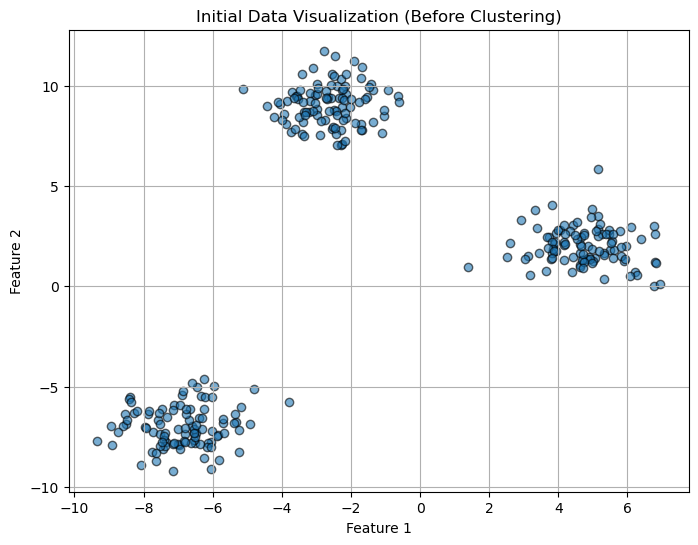

In [7]:
# Generate synthetic data with clusters
X, _ = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)

# Convert to DataFrame
data = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])

# Initial EDA: Scatter plot of raw data
plt.figure(figsize=(8, 6))
plt.scatter(data['Feature_1'], data['Feature_2'], alpha=0.6, edgecolors='k')
plt.title('Initial Data Visualization (Before Clustering)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

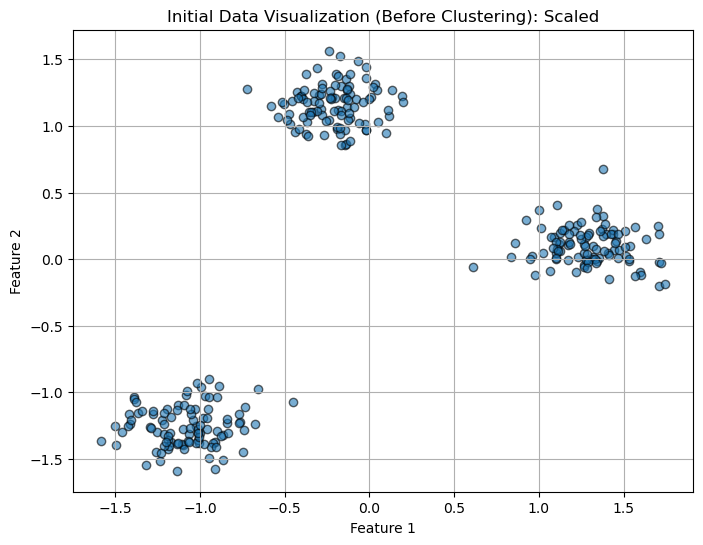

In [8]:
# standardize
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

# Scatter plot of scaled data
plt.figure(figsize=(8, 6))
plt.scatter(data_scaled[:, 0], data_scaled[:, 1], alpha=0.6, edgecolors='k') # Access columns by index
plt.title('Initial Data Visualization (Before Clustering): Scaled')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

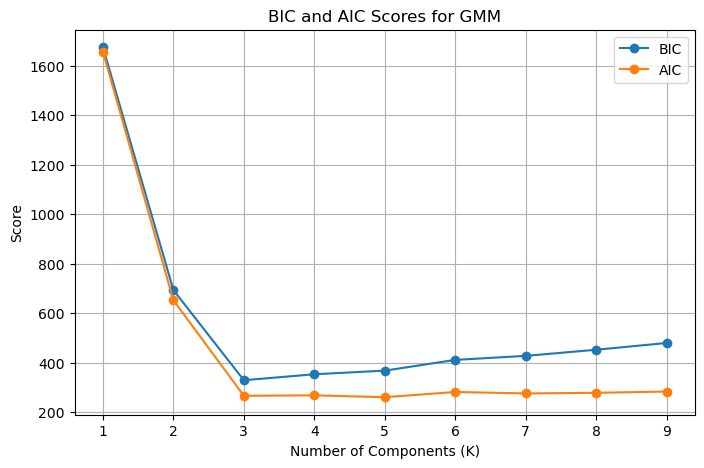

In [9]:
# Use the Elbow Method or BIC/AIC to determine an optimal K.
# Default to K=3 or K=4 if exploratory analysis is not required.
bic_scores = []
aic_scores = []
k_values = range(1, 10)

for k in k_values:
    gmm = GaussianMixture(n_components=k, random_state=42, n_init=10)
    gmm.fit(data_scaled)
    bic_scores.append(gmm.bic(data_scaled))
    aic_scores.append(gmm.aic(data_scaled))

# Plot BIC and AIC to find optimal K
plt.figure(figsize=(8, 5))
plt.plot(k_values, bic_scores, marker='o', linestyle='-', label='BIC')
plt.plot(k_values, aic_scores, marker='o', linestyle='-', label='AIC')
plt.xlabel('Number of Components (K)')
plt.ylabel('Score')
plt.legend()
plt.title('BIC and AIC Scores for GMM')
plt.grid(True)
plt.show()

In [10]:
optimal_k = 3  # Adjust based on BIC/AIC analysis
gmm = GaussianMixture(n_components=optimal_k, random_state=42, n_init=10)
gmm.fit(data_scaled)

# Predict cluster probabilities
probs = gmm.predict_proba(data_scaled)

# Assign clusters based on max probability
cluster_assignments = gmm.predict(data_scaled)

In [11]:
# Compute minimum probability per point
min_prob = np.min(probs, axis=1)

# Define anomaly threshold (5th percentile)
threshold = np.percentile(min_prob, 5)

# Identify anomalies
anomalies = data[min_prob < threshold]

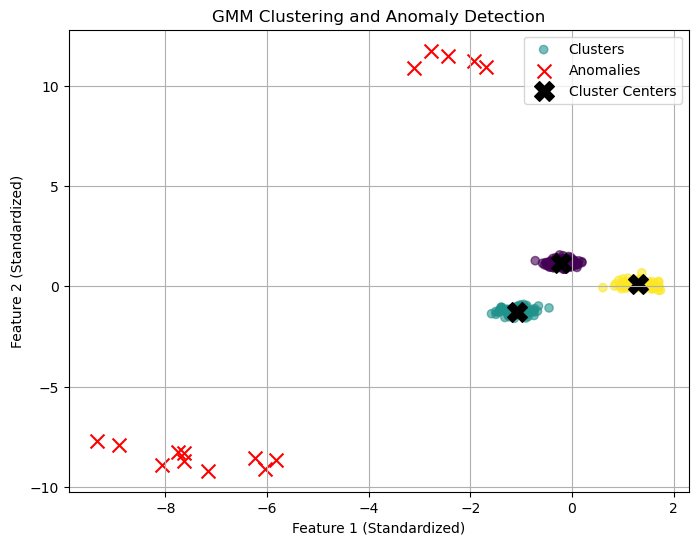

In [12]:
plt.figure(figsize=(8, 6))

# Scatter plot of all data points
plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c=cluster_assignments, cmap='viridis', alpha=0.6, label="Clusters")

# Highlight anomalies
plt.scatter(anomalies['Feature_1'], anomalies['Feature_2'], color='red', marker='x', s=100, label="Anomalies")

# Plot cluster centers
plt.scatter(gmm.means_[:, 0], gmm.means_[:, 1], s=200, c='black', marker='X', label="Cluster Centers")

plt.title('GMM Clustering and Anomaly Detection')
plt.xlabel('Feature 1 (Standardized)')
plt.ylabel('Feature 2 (Standardized)')
plt.legend()
plt.grid(True)
plt.show()

Standardized Data Plot (Range: ~ -2 to 2): Data is standardized to have mean = 0, std = 1.
GMM Clustering & Anomalies Plot (Range: ~ -10 to 10): The Gaussian mixture components estimate new means and covariances, which can result in a broader display range due to probability-based cluster assignments.

## Mall Customers Dataset

In [13]:
# load dataset
mall_df = pd.read_csv("../Datasets/Mall_Customers.csv")
print(mall_df.shape)
mall_df.head()

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [14]:
mall_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [15]:
mall_df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [16]:
mall_df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

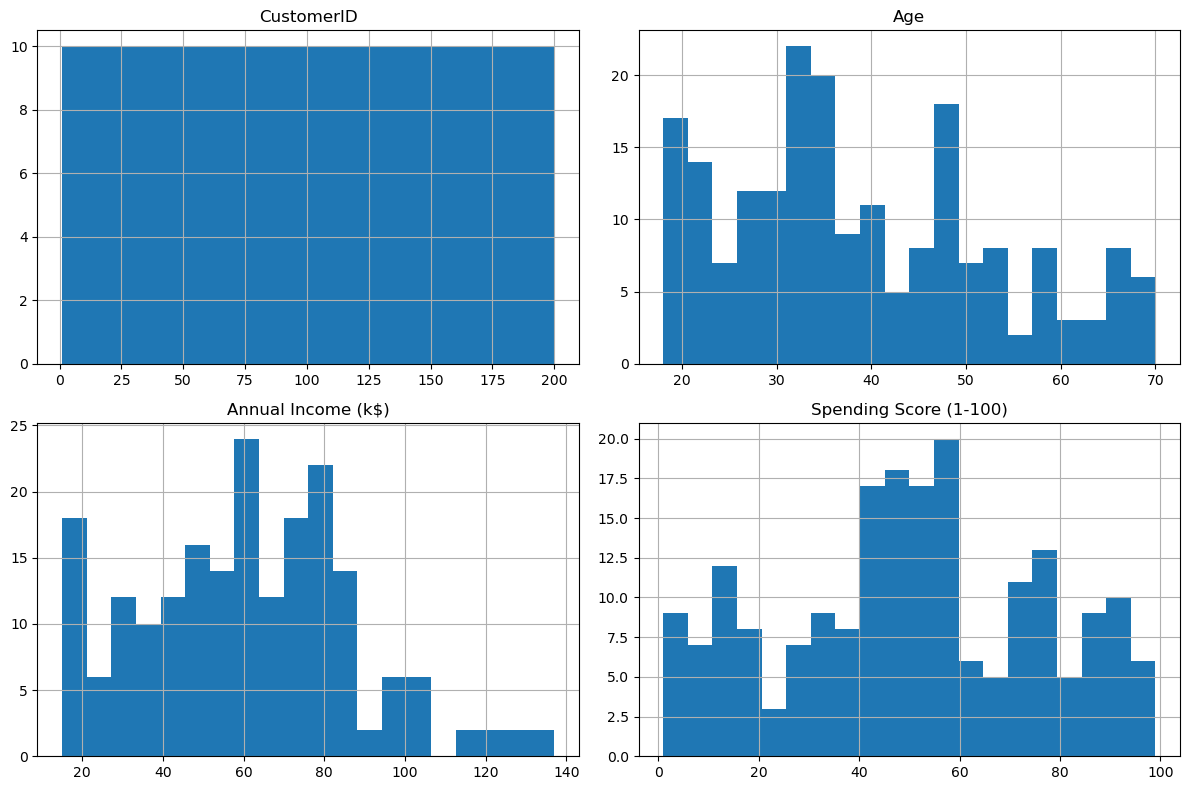

In [17]:
# distributions
mall_df.hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

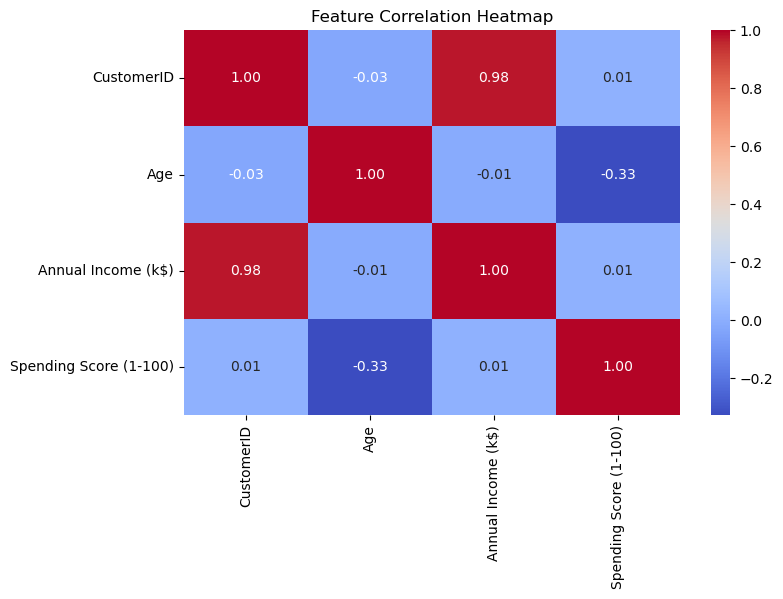

In [21]:
# correlation
numeric_df = mall_df.select_dtypes(include=np.number)

plt.figure(figsize=(8, 5))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [24]:
# Preprocessing
X = mall_df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

In [25]:
# standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled,columns=X.columns,index=X.index)
X_scaled.head()

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


In [27]:
# Modelling
gmm = GaussianMixture(n_components=5,random_state=42)

gmm_clusters = gmm.fit_predict(X_scaled)

mall_df['GMM_Cluster'] = gmm_clusters

In [29]:
# cluster assignments
mall_df[['Annual Income (k$)', 'Spending Score (1-100)', 'GMM_Cluster']].head(10)

,Annual Income (k$),Spending Score (1-100),GMM_Cluster
0,15,39,4
1,15,81,2
2,16,6,4
3,16,77,2
4,17,40,4
5,17,76,2
6,18,6,4
7,18,94,2
8,19,3,4
9,19,72,2


In [31]:
mall_df['GMM_Cluster'].nunique()

5

In [33]:
# cluster distribution
mall_df['GMM_Cluster'].value_counts().sort_index()

GMM_Cluster
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

In [34]:
# evaluation
silhouette = silhouette_score(X_scaled, gmm_clusters)
db_index = davies_bouldin_score(X_scaled, gmm_clusters)
ch_score = calinski_harabasz_score(X_scaled, gmm_clusters)

print("Silhouette Score:", silhouette)
print("Davies-Bouldin Index:", db_index)
print("Calinski-Harabasz Score:", ch_score)

Silhouette Score: 0.5536892843811245
Davies-Bouldin Index: 0.5760100302410824
Calinski-Harabasz Score: 244.9401969858632


In [35]:
# hyperparameter tuning
results = []

for n in range(2, 11):
    model = GaussianMixture(n_components=n,random_state=42)

    model.fit(X_scaled)

    results.append({
        'Components': n,
        'AIC': model.aic(X_scaled),
        'BIC': model.bic(X_scaled)
    })

gmm_results = pd.DataFrame(results)

gmm_results

,Components,AIC,BIC
0,2,1117.623164,1153.904655
1,3,1095.646879,1151.718274
2,4,1027.928849,1103.790149
3,5,963.001049,1058.652252
4,6,959.241699,1074.682807
5,7,952.097505,1087.328517
6,8,947.349785,1102.370701
7,9,931.995005,1106.805826
8,10,933.017464,1127.618189


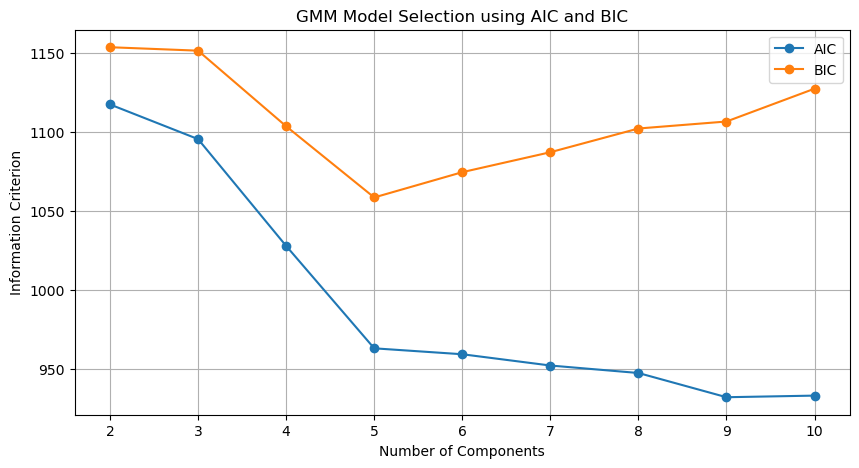

In [36]:
plt.figure(figsize=(10, 5))

plt.plot(gmm_results['Components'], gmm_results['AIC'],
         marker='o', label='AIC')

plt.plot(gmm_results['Components'], gmm_results['BIC'],
         marker='o', label='BIC')

plt.xlabel('Number of Components')
plt.ylabel('Information Criterion')
plt.title('GMM Model Selection using AIC and BIC')
plt.legend()
plt.grid(True)
plt.show()

In [38]:
gmm_final = GaussianMixture(n_components=5,random_state=42)

final_clusters = gmm_final.fit_predict(X_scaled)

mall_df['GMM_Final_Cluster'] = final_clusters

In [39]:
mall_df['GMM_Final_Cluster'].value_counts().sort_index()

GMM_Final_Cluster
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

In [40]:
silhouette_final = silhouette_score(X_scaled, final_clusters)
db_index_final = davies_bouldin_score(X_scaled, final_clusters)
ch_score_final = calinski_harabasz_score(X_scaled, final_clusters)

print("Final Silhouette Score:", silhouette_final)
print("Final Davies-Bouldin Index:", db_index_final)
print("Final Calinski-Harabasz Score:", ch_score_final)

Final Silhouette Score: 0.5536892843811245
Final Davies-Bouldin Index: 0.5760100302410824
Final Calinski-Harabasz Score: 244.9401969858632


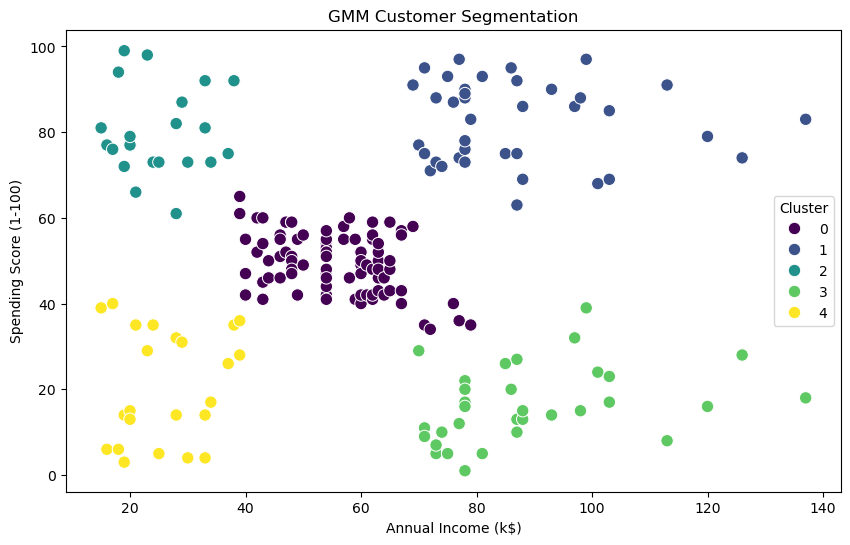

In [42]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=mall_df,x='Annual Income (k$)',y='Spending Score (1-100)',hue='GMM_Final_Cluster',palette='viridis',s=80)

plt.title('GMM Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.show()

In [44]:
# cluster profiling
cluster_profile = mall_df.groupby('GMM_Final_Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean()

cluster_profile

,Annual Income (k$),Spending Score (1-100)
GMM_Final_Cluster,,
0,55.642857,49.369048
1,86.538462,82.128205
2,25.095238,80.047619
3,88.818182,16.000000
4,26.304348,20.913043


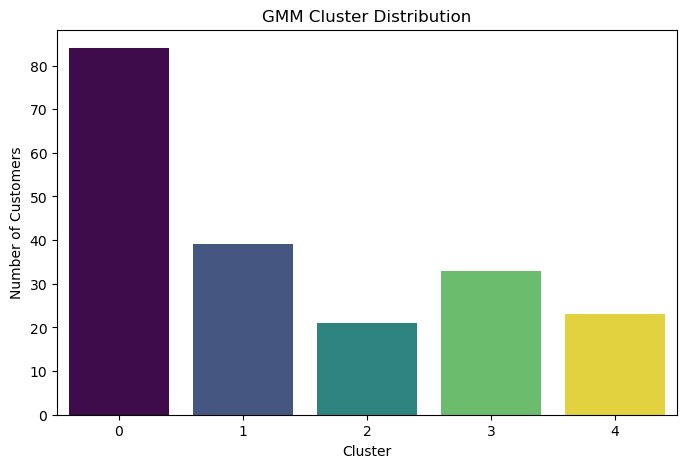

In [45]:
plt.figure(figsize=(8, 5))

sns.countplot(data=mall_df,x='GMM_Final_Cluster',hue='GMM_Final_Cluster',palette='viridis',legend=False)

plt.title('GMM Cluster Distribution')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.show()

## Conclusion – Gaussian Mixture Models (GMM)

GMM was applied to the Mall Customers dataset using Annual Income and Spending Score. The features were standardized before modelling.

The final model used **5 Gaussian components**, selected based on the BIC criterion.

### Model Evaluation
- Number of clusters: 5
- Silhouette Score: 0.5537
- Davies-Bouldin Index: 0.5760
- Calinski-Harabasz Score: 244.94

### Cluster Interpretation
- **Cluster 0:** Average-income customers with moderate spending scores.
- **Cluster 1:** High-income customers with high spending scores.
- **Cluster 2:** Low-income customers with high spending scores.
- **Cluster 3:** High-income customers with low spending scores.
- **Cluster 4:** Low-income customers with low spending scores.

### Final Observation
GMM successfully identified five customer segments with different income and spending characteristics. Its probabilistic approach allows observations to have varying membership probabilities rather than assigning them exclusively through distance-based boundaries.

Overall, GMM demonstrated its usefulness for customer segmentation by identifying distinct patterns in the dataset.